In [ ]:
# ============================================================
# ZIP POPULATION DENSITY MAP (Cartopy, CUSTOM COUNTY MASK)
# NO ISLANDS — FINAL, PDF-SAFE VERSION (FIXED COLORBAR)
# Original code by Jorge Ceilis and DJ Gagne.
# Appended and edited by Gabrielle Gantos.
# ============================================================

import geopandas as gpd
import pandas as pd
import requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from shapely.geometry import LineString
import cartopy.crs as ccrs

CRS_MAP = "EPSG:4326"
CRS_PROJ = "EPSG:3310"

# ------------------------------------------------------------
# 1. Load CUSTOM county boundaries (NO islands)
# ------------------------------------------------------------
custom_counties_path = (
    "/glade/work/jcelis/code/jcelis/2.mobility_code/"
    "Paper_figures_Code/county_shapes.shp"
)
custom_counties = gpd.read_file(custom_counties_path).to_crs(CRS_PROJ)

# ------------------------------------------------------------
# 2. TIGER counties (INSET ONLY)
# ------------------------------------------------------------
county_url = (
    "https://www2.census.gov/geo/tiger/TIGER2023/COUNTY/"
    "tl_2023_us_county.zip"
)
counties = gpd.read_file(county_url)

ca = counties[counties["STATEFP"] == "06"]
study_names = ["Santa Barbara", "Ventura", "Los Angeles"]
study_counties = ca[ca["NAME"].isin(study_names)]

# ------------------------------------------------------------
# 3. Load ZCTA polygons
# ------------------------------------------------------------
zcta_url = (
    "https://www2.census.gov/geo/tiger/TIGER2023/ZCTA520/"
    "tl_2023_us_zcta520.zip"
)
zcta = gpd.read_file(zcta_url)
zcta = zcta.rename(columns={"ZCTA5CE20": "ZCTA"})
zcta["ZCTA"] = zcta["ZCTA"].astype(str)
zcta = zcta.to_crs(CRS_PROJ)

# ------------------------------------------------------------
# 4. Spatial join ZCTAs → CUSTOM counties
# ------------------------------------------------------------
zcta_with_county = gpd.sjoin(
    zcta,
    custom_counties[["geometry"]],
    predicate="intersects",
    how="inner"
)

# ------------------------------------------------------------
# 5. ACS population
# ------------------------------------------------------------
acs_url = (
    "https://api.census.gov/data/2023/acs/acs5"
    "?get=B01003_001E&for=zip%20code%20tabulation%20area:*"
)
acs_json = requests.get(acs_url).json()
acs_df = pd.DataFrame(acs_json[1:], columns=acs_json[0])

acs_df = acs_df.rename(columns={"zip code tabulation area": "ZCTA"})
acs_df["ZCTA"] = acs_df["ZCTA"].astype(str)
acs_df["population"] = pd.to_numeric(acs_df["B01003_001E"], errors="coerce")

# ------------------------------------------------------------
# 6. Merge + density (STRICT CLIP = no islands)
# ------------------------------------------------------------
merged = zcta_with_county.merge(
    acs_df[["ZCTA", "population"]],
    on="ZCTA",
    how="left"
)

merged["area_sqkm"] = merged.geometry.area / 1e6
merged["pop_density"] = merged["population"] / merged["area_sqkm"]

# 🔒 Strict clip to custom counties
heatmap_polys = gpd.clip(merged, custom_counties)

# Clean: drop null/zero densities to avoid LogNorm issues
heatmap_polys = heatmap_polys.dropna(subset=["pop_density"])
heatmap_polys = heatmap_polys[heatmap_polys["pop_density"] > 0]

# ------------------------------------------------------------
# 7. Fetch highways (OSM) + clip to custom counties
# ------------------------------------------------------------

print("Fetching highways from OSM…")

bbox = custom_counties.to_crs(CRS_MAP).total_bounds
minx, miny, maxx, maxy = bbox

overpass_query = f"""
[out:json][timeout:180];
(
  way["highway"~"motorway|trunk|primary"]({miny},{minx},{maxy},{maxx});
);
out geom;
"""

highways_gdf = None

try:
    response = requests.get(
        "http://overpass-api.de/api/interpreter",
        params={"data": overpass_query},
        timeout=180
    )
    response.raise_for_status()
    osm_data = response.json()

    highways = []
    for el in osm_data.get("elements", []):
        if el["type"] == "way" and "geometry" in el:
            coords = [(p["lon"], p["lat"]) for p in el["geometry"]]
            if len(coords) > 1:
                highways.append({"geometry": LineString(coords)})

    if highways:
        highways_gdf = gpd.GeoDataFrame(
            highways, crs=CRS_MAP
        )
        highways_gdf = gpd.clip(
            highways_gdf,
            custom_counties.to_crs(CRS_MAP)
        )

except Exception as e:
    print("⚠ Overpass API failed — proceeding without highways.")
    print(e)


# ------------------------------------------------------------
# 8. MAIN MAP (Cartopy)
# ------------------------------------------------------------
fig = plt.figure(figsize=(12, 11))
ax = plt.axes(projection=ccrs.PlateCarree())

# Leave room on the right for a fixed colorbar axis
fig.subplots_adjust(left=0.05, right=0.88, bottom=0.06, top=0.92)

norm = colors.LogNorm(
    vmin=max(1, float(heatmap_polys["pop_density"].min())),
    vmax=float(heatmap_polys["pop_density"].max())
)

heatmap_polys.to_crs(CRS_MAP).plot(
    ax=ax,
    column="pop_density",
    cmap="plasma",
    norm=norm,
    linewidth=0,
    zorder=2
)

# Highways overlay
if highways_gdf is not None and not highways_gdf.empty:
    highways_gdf.plot(
        ax=ax,
        color="gray",
        linewidth=1.1,
        alpha=0.85,
        zorder=3
    )

# Custom county outline (no islands)
custom_counties.to_crs(CRS_MAP).boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=2.0,
    zorder=4
)

# Labels with halo
for _, row in study_counties.to_crs(CRS_MAP).iterrows():
    x, y = row.geometry.representative_point().coords[0]
    ax.text(
        x, y,
        row["NAME"],
        fontsize=15,
        weight="bold",
        color="black",
        ha="center",
        va="center",
        zorder=5,
        path_effects=[pe.withStroke(linewidth=4, foreground="white")]
    )

ax.set_extent([minx - 0.2, maxx + 0.2, miny - 0.2, maxy + 0.2])

ax.set_title(
    "Population Density by ZIP Code (Log Scale)\n"
    "Santa Barbara, Ventura, and Los Angeles Counties",
    fontsize=18,
    pad=14
)

# ------------------------------------------------------------
# 9. COLORBAR (fixed axis; DO NOT use tight_layout)
# ------------------------------------------------------------
cax = fig.add_axes([0.90, 0.12, 0.02, 0.78])  # [left, bottom, width, height]
sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
sm.set_array(np.array([norm.vmin, norm.vmax]))  # ensures it renders in PDF
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Population Density (people per sq km, log scale)", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 10. California inset
# ------------------------------------------------------------
ax_inset = inset_axes(ax, width="35%", height="35%", loc="lower left", borderpad=1.4)

ca.to_crs(CRS_MAP).plot(
    ax=ax_inset,
    facecolor="none",
    edgecolor="lightgray",
    linewidth=0.6
)
study_counties.to_crs(CRS_MAP).plot(
    ax=ax_inset,
    facecolor="none",
    edgecolor="black",
    linewidth=1.4
)

rect = Rectangle(
    (minx, miny),
    maxx - minx,
    maxy - miny,
    fill=False,
    linewidth=1.2,
    edgecolor="black"
)
ax_inset.add_patch(rect)

ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_title("California", fontsize=10)

# ------------------------------------------------------------
# 11. Save + show
# ------------------------------------------------------------
fig.canvas.draw()  # important for consistent rendering
fig.savefig("Fig1_CA_ZIP_pop_12182025.pdf", dpi=300)  # no bbox_inches
plt.show()


In [1]:
# ============================================================
# ZIP POPULATION DENSITY MAP (Cartopy, CUSTOM COUNTY MASK)
# NO ISLANDS — FINAL, PDF-SAFE VERSION (ROBUST OSM HIGHWAYS)
# ============================================================

import geopandas as gpd
import pandas as pd
import requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from shapely.geometry import LineString
import cartopy.crs as ccrs

CRS_MAP = "EPSG:4326"
CRS_PROJ = "EPSG:3310"

# ------------------------------------------------------------
# 0. Helper: robust Overpass fetch (tries multiple servers)
# ------------------------------------------------------------
OVERPASS_ENDPOINTS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass.nchc.org.tw/api/interpreter",
]

def fetch_osm_highways_bbox(minx, miny, maxx, maxy, timeout_s=300):
    """
    Fetch OSM highways for bbox using a lighter Overpass pattern:
      - First get ways with out skel
      - Then fetch all node geometry with '>'
      - Finally out geom
    """
    # Note: bbox order in Overpass is (south, west, north, east)
    query = f"""
    [out:json][timeout:{timeout_s}];
    (
      way["highway"~"motorway|trunk|primary"]({miny},{minx},{maxy},{maxx});
    );
    out skel qt;
    >;
    out geom qt;
    """

    last_err = None
    for url in OVERPASS_ENDPOINTS:
        try:
            r = requests.get(url, params={"data": query}, timeout=timeout_s)
            r.raise_for_status()
            return r.json(), url
        except Exception as e:
            last_err = e

    raise RuntimeError(f"All Overpass endpoints failed. Last error: {last_err}")

def osm_json_to_gdf(osm_data, clip_geom_gdf_wgs84):
    """
    Convert Overpass JSON ways w/ geometry to GeoDataFrame (EPSG:4326),
    then clip to clip_geom_gdf_wgs84.
    """
    highways = []
    for el in osm_data.get("elements", []):
        if el.get("type") == "way" and "geometry" in el:
            coords = [(p["lon"], p["lat"]) for p in el["geometry"]]
            if len(coords) > 1:
                highways.append({"geometry": LineString(coords)})

    if not highways:
        return None

    gdf = gpd.GeoDataFrame(highways, crs=CRS_MAP)
    gdf = gpd.clip(gdf, clip_geom_gdf_wgs84)
    return gdf

# ------------------------------------------------------------
# 1. Load CUSTOM county boundaries (NO islands)
# ------------------------------------------------------------
custom_counties_path = (
    "/glade/work/jcelis/code/jcelis/2.mobility_code/"
    "Paper_figures_Code/county_shapes.shp"
)
custom_counties = gpd.read_file(custom_counties_path).to_crs(CRS_PROJ)

# ------------------------------------------------------------
# 2. TIGER counties (INSET ONLY)
# ------------------------------------------------------------
county_url = (
    "https://www2.census.gov/geo/tiger/TIGER2023/COUNTY/"
    "tl_2023_us_county.zip"
)
counties = gpd.read_file(county_url)

ca = counties[counties["STATEFP"] == "06"]
study_names = ["Santa Barbara", "Ventura", "Los Angeles"]
study_counties = ca[ca["NAME"].isin(study_names)]

# ------------------------------------------------------------
# 3. Load ZCTA polygons
# ------------------------------------------------------------
zcta_url = (
    "https://www2.census.gov/geo/tiger/TIGER2023/ZCTA520/"
    "tl_2023_us_zcta520.zip"
)
zcta = gpd.read_file(zcta_url)
zcta = zcta.rename(columns={"ZCTA5CE20": "ZCTA"})
zcta["ZCTA"] = zcta["ZCTA"].astype(str)
zcta = zcta.to_crs(CRS_PROJ)

# ------------------------------------------------------------
# 4. Spatial join ZCTAs → CUSTOM counties
# ------------------------------------------------------------
zcta_with_county = gpd.sjoin(
    zcta,
    custom_counties[["geometry"]],
    predicate="intersects",
    how="inner"
)

In [2]:
# ------------------------------------------------------------
# 5. ACS population
# ------------------------------------------------------------
HOST = "https://api.census.gov/data"
YEAR = "2023"  # Change to your target year
DATASET = "acs/acs5"  # acs5 = 5-year estimates; use acs1 for 1-year profiles
BASE_URL = f"{HOST}/{YEAR}/{DATASET}"

params = {
    "get": "NAME,B01003_001E",
    "for": "zip code tabulation area:*",  # Wildcard (*) fetches all states
    "key": "0bcf05d2f39d4f957b75b36d012e69f370c3e8ec", # Optional, but recommended for high volume
}
response = requests.get(BASE_URL, params=params)

# acs_url = (
#     "https://api.census.gov/data/2023/acs/acs5"
#     "?get=B01003_001E&for=zip%20code%20tabulation%20area:*"
# )
# response = requests.get(acs_url)
if response.status_code == 200:
    print("Success! Data retrieved.")
    acs_json =  response.json()
    
acs_df = pd.DataFrame(acs_json[1:], columns=acs_json[0])
acs_df = acs_df.rename(columns={"zip code tabulation area": "ZCTA"})
acs_df["ZCTA"] = acs_df["ZCTA"].astype(str)
acs_df["population"] = pd.to_numeric(acs_df["B01003_001E"], errors="coerce")

Success! Data retrieved.


In [3]:
# ------------------------------------------------------------
# 6. Merge + density (STRICT CLIP = no islands)
# ------------------------------------------------------------
merged = zcta_with_county.merge(
    acs_df[["ZCTA", "population"]],
    on="ZCTA",
    how="left"
)

merged["area_sqkm"] = merged.geometry.area / 1e6
merged["pop_density"] = merged["population"] / merged["area_sqkm"]

heatmap_polys = gpd.clip(merged, custom_counties)
heatmap_polys = heatmap_polys.dropna(subset=["pop_density"])
heatmap_polys = heatmap_polys[heatmap_polys["pop_density"] > 0]


In [15]:
# ------------------------------------------------------------
# 7. Fetch highways (OSM) — ROBUST + FALLBACK
# ------------------------------------------------------------
print("Fetching highways from OSM…")

# Get bbox in EPSG:4326
bbox = custom_counties.to_crs(CRS_MAP).total_bounds
minx, miny, maxx, maxy = bbox

# Expand bbox slightly (IMPORTANT)
pad = 0.1
minx -= pad
miny -= pad
maxx += pad
maxy += pad

overpass_query = f"""
[out:json][timeout:300];
(
  way["highway"~"motorway|trunk|primary|secondary"]({miny},{minx},{maxy},{maxx});
);
out geom;
"""

overpass_endpoints = [
    "https://overpass.kumi.systems/api/interpreter",
    "https://overpass-api.de/api/interpreter",
    "https://overpass.nchc.org.tw/api/interpreter"
]

highways_gdf = None

for endpoint in overpass_endpoints:
    try:
        print(f"✓ Trying Overpass endpoint: {endpoint}")
        r = requests.post(endpoint, data=overpass_query, timeout=300)
        r.raise_for_status()
        osm_data = r.json()

        if not osm_data.get("elements"):
            print("⚠ No highways returned from this endpoint.")
            continue

        highways = []
        for el in osm_data["elements"]:
            if el["type"] == "way" and "geometry" in el:
                coords = [(p["lon"], p["lat"]) for p in el["geometry"]]
                if len(coords) > 1:
                    highways.append({"geometry": LineString(coords)})

        if highways:
            highways_gdf = gpd.GeoDataFrame(highways, crs=CRS_MAP)
            highways_gdf = gpd.clip(
                highways_gdf,
                custom_counties.to_crs(CRS_MAP)
            )
            print(f"✓ Highways fetched from: {endpoint}")
            break

    except Exception as e:
        print(f"⚠ Overpass failed at {endpoint}: {e}")

if highways_gdf is None or highways_gdf.empty:
    print("⚠ No highways available — map will render without roads.")


Fetching highways from OSM…
✓ Trying Overpass endpoint: https://overpass.kumi.systems/api/interpreter
⚠ Overpass failed at https://overpass.kumi.systems/api/interpreter: 429 Client Error: Too Many Requests for url: https://overpass.kumi.systems/api/interpreter
✓ Trying Overpass endpoint: https://overpass-api.de/api/interpreter
⚠ Overpass failed at https://overpass-api.de/api/interpreter: 406 Client Error: Not Acceptable for url: https://overpass-api.de/api/interpreter
✓ Trying Overpass endpoint: https://overpass.nchc.org.tw/api/interpreter
⚠ Overpass failed at https://overpass.nchc.org.tw/api/interpreter: HTTPSConnectionPool(host='overpass.nchc.org.tw', port=443): Max retries exceeded with url: /api/interpreter (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x149f8fe3cad0>: Failed to resolve 'overpass.nchc.org.tw' ([Errno -2] Name or service not known)"))
⚠ No highways available — map will render without roads.


In [22]:
from awips.dataaccess import DataAccessLayer
from cartopy.feature import ShapelyFeature
from cartopy import crs as ccrs
import geopandas as gpd
import cartopy.feature as cfeature
from shapely.geometry import Polygon
# import pyproj

# lcc = pyproj.CRS(
#     "+proj=lcc +lat_1=25 +lat_2=60 +lat_0=42.5 +lon_0=-100 +datum=WGS84 +units=m"
# )
# Get bbox in EPSG:4326
bbox = custom_counties.to_crs(CRS_MAP).total_bounds
minx, miny, maxx, maxy = bbox
region = [minx, maxx, miny, maxy]
region_envelope = Polygon([(region[0],region[2]),(region[0],region[3]),
                          (region[1],region[3]),(region[1],region[2]),
                          (region[0],region[2])])

DataAccessLayer.changeEDEXHost("edex-cloud.unidata.ucar.edu")
# request = DataAccessLayer.newDataRequest('maps', envelope=region_envelope)
# request.addIdentifier('table', 'mapdata.interstate')
# request.addIdentifier('geomField', 'the_geom')
# interstates = DataAccessLayer.getGeometryData(highway_response)
# print("Using " + str(len(interstates)) + " interstate MultiLineStrings")
# interstates_sh = ShapelyFeature([ob.getGeometry() for ob in interstates],ccrs.PlateCarree(),
#                             facecolor='none', linestyle="-", edgecolor='Sienna', lw=1)
highway_request = DataAccessLayer.newDataRequest("maps")
highway_request.addIdentifier("table", "mapdata.highway")
highway_request.addIdentifier("geomField", "the_geom")
highway_request.setEnvelope(region_envelope)
highway_response = DataAccessLayer.getGeometryData(highway_request)
highway_sh = ShapelyFeature([ob.getGeometry() for ob in highway_response],ccrs.PlateCarree(),
                            facecolor='none', linestyle="-", edgecolor='Sienna', lw=1)

geoms = list(highway_sh.geometries())
highways_gdf = gpd.GeoDataFrame(geometry=geoms, crs=highway_sh.crs.proj4_init)


In [40]:
import urllib3
import json
import xarray as xr

# Load Flash Flood Warning Polygons
req = urllib3.request("GET", "https://mesonet.agron.iastate.edu/api/1/cow.json?wfo=LOX&begints=2024-03-28T12:00:00Z&enable_shared_border=1&endts=2024-03-31T12:00:00Z&hailsize=1&wind=58&phenomena=FF&lsrbuffer=15&warningbuffer=1")
ffws = json.loads(req.data)
rain_ds = xr.open_dataset("/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc")
rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").max() / 25.4

<xarray.DataArray 'MultiSensor_QPE_01H_Pass2_00.00_sum' ()> Size: 8B
array(4.93700787)
Coordinates:
    time     datetime64[ns] 8B 2024-03-30

/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/geopandas/plotting.py:51: ShapelyDeprecationWarning: The 'type' attribute is deprecated, and will be removed in the future. You can use the 'geom_type' attribute instead.
  if geom is not None and geom.type.startswith(prefix) and not geom.is_empty:
/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/geopandas/plotting.py:51: ShapelyDeprecationWarning: The 'type' attribute is deprecated, and will be removed in the future. You can use the 'geom_type' attribute instead.
  if geom is not None and geom.type.startswith(prefix) and not geom.is_empty:


[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/geopandas/plotting.py:51: ShapelyDeprecationWarning: The 'type' attribute is deprecated, and will be removed in the future. You can use the 'geom_type' attribute instead.
  if geom is not None and geom.type.startswith(prefix) and not geom.is_empty:
/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/geopandas/plotting.py:51: ShapelyDeprecationWarning: The 'type' attribute is deprecated, and will be removed in the future. You can use the 'geom_type' attribute instead.
  if geom is not None and geom.type.startswith(prefix) and not geom.is_empty:
/glade/work/ggantos/conda-envs/cat/lib/python3.11/site-packages/geopandas/plotting.py:51: ShapelyDeprecationWarning: The 'type' attribute is deprecated, and will be removed in the future. You can use the 'geom_type' attribute instead.
  if geom is not None and geom.type.startswith(prefix) and not geom.is_empty:


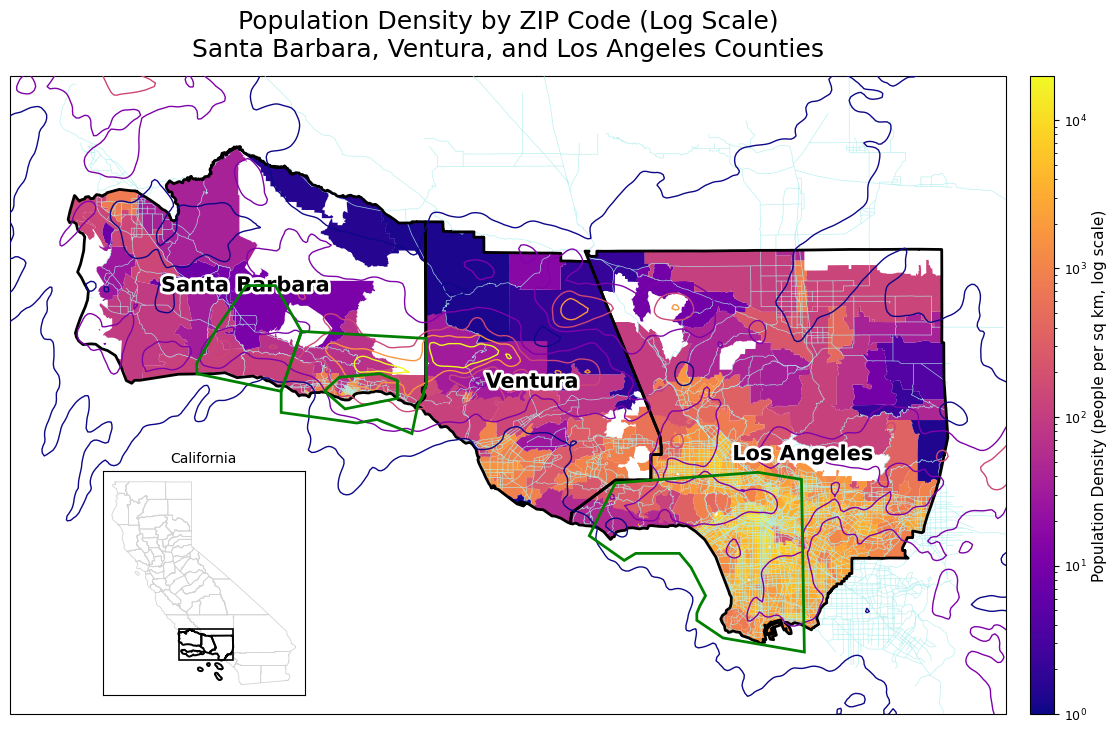

In [52]:
from scipy.ndimage import gaussian_filter
# ------------------------------------------------------------
# 8. MAIN MAP (Cartopy)
# ------------------------------------------------------------
fig = plt.figure(figsize=(12, 11))
ax = plt.axes(projection=ccrs.PlateCarree())

# Leave room on the right for a fixed colorbar axis
fig.subplots_adjust(left=0.05, right=0.88, bottom=0.06, top=0.92)

norm = colors.LogNorm(
    vmin=max(1, float(heatmap_polys["pop_density"].min())),
    vmax=float(heatmap_polys["pop_density"].max())
)

heatmap_polys.to_crs(CRS_MAP).plot(
    ax=ax,
    column="pop_density",
    cmap="plasma",
    norm=norm,
    linewidth=0,
    zorder=2
)


# Flash flood warnings overlay
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    ax.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2, zorder=6)


# MRMS rain contour overlay
rain_cont = ax.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0, zorder=5)

# Highways overlay
if highways_gdf is not None and not highways_gdf.empty:
    highways_gdf.plot(
        ax=ax,
        color="paleturquoise",
        linewidth=0.5,
        alpha=0.85,
        zorder=3
    )

# Custom county outline (no islands)
custom_counties.to_crs(CRS_MAP).boundary.plot(
    ax=ax,
    edgecolor="black",
    linewidth=2.0,
    zorder=4
)


# Labels with halo
for _, row in study_counties.to_crs(CRS_MAP).iterrows():
    x, y = row.geometry.representative_point().coords[0]
    ax.text(
        x, y,
        row["NAME"],
        fontsize=15,
        weight="bold",
        color="black",
        ha="center",
        va="center",
        zorder=5,
        path_effects=[pe.withStroke(linewidth=4, foreground="white")]
    )

ax.set_extent([minx - 0.2, maxx + 0.2, miny - 0.2, maxy + 0.2])

ax.set_title(
    "Population Density by ZIP Code (Log Scale)\n"
    "Santa Barbara, Ventura, and Los Angeles Counties",
    fontsize=18,
    pad=14
)

# ------------------------------------------------------------
# 9. COLORBAR (fixed axis; PDF-safe)
# ------------------------------------------------------------

cax = fig.add_axes([0.90, 0.2, 0.02, 0.58])
sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
sm.set_array(np.array([norm.vmin, norm.vmax]))
cbar = fig.colorbar(sm, cax=cax, shrink=0.7)
cbar.set_label("Population Density (people per sq km, log scale)", fontsize=11)
cbar.ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 10. California inset
# ------------------------------------------------------------
ax_inset = inset_axes(ax, width="35%", height="35%", loc="lower left", borderpad=1.4)

ca.to_crs(CRS_MAP).plot(
    ax=ax_inset,
    facecolor="none",
    edgecolor="lightgray",
    linewidth=0.6
)
study_counties.to_crs(CRS_MAP).plot(
    ax=ax_inset,
    facecolor="none",
    edgecolor="black",
    linewidth=1.4
)

rect = Rectangle((minx, miny), maxx - minx, maxy - miny,
                 fill=False, linewidth=1.2, edgecolor="black")
ax_inset.add_patch(rect)

ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_title("California", fontsize=10)

# ------------------------------------------------------------
# 11. Save + show
# ------------------------------------------------------------
fig.canvas.draw()
fig.savefig("Fig1_CA_ZIP_pop_12182025.pdf", dpi=300)
plt.show()
